henon.py — Hénon Map (OGY 1990)

[1] Running sanity checks ...
    PASS  step_from_origin
    PASS  jacobian_correct
    PASS  trajectory_length
    PASS  warmup_on_attractor
    PASS  noise_adds_variation

    All checks passed.

[2] Attractor statistics (A=1.4, B=0.3, 100k points) ...
    x range : [-1.7985,  1.7822]
    y range : [-1.7985,  1.7822]
    x mean  : 0.362561  (expected ~0.63)
    y mean  : 0.362560  (expected ~0.63)

[3] Sampling 5 random initial conditions on the attractor ...
    IC 1: x = 1.180678,  y = -0.803415
    IC 2: x = 1.782057,  y = -0.060239
    IC 3: x = -0.759066,  y = 1.512334
    IC 4: x = 1.290784,  y = -0.750316
    IC 5: x = 1.465612,  y = 0.423619

[4] Generating plots ...
    Saved: henon_demo.png


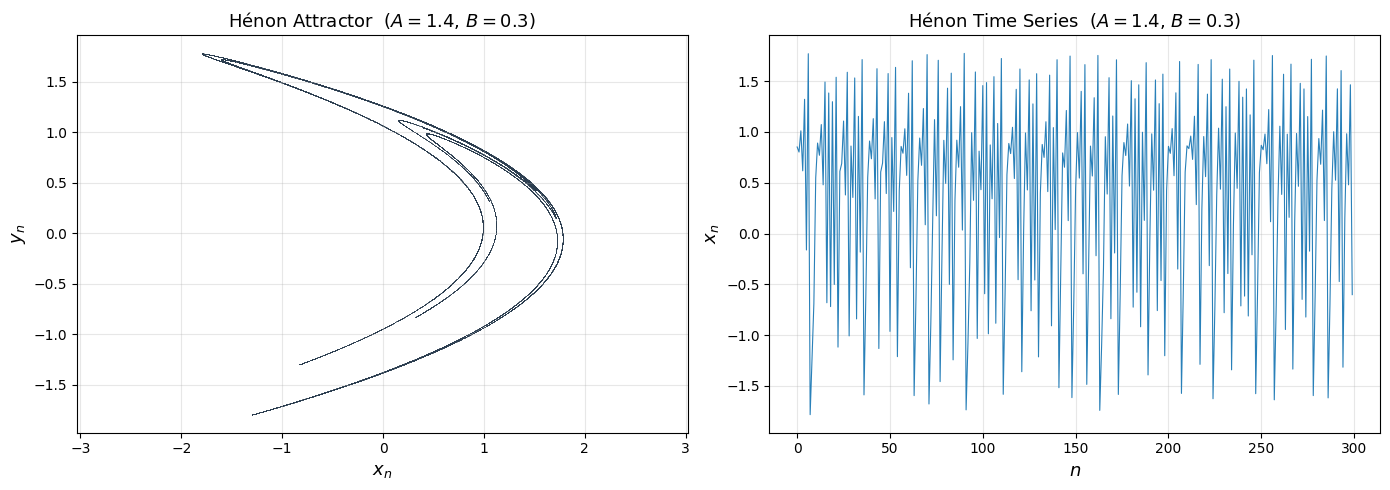


Done.


In [2]:
"""
henon.py — Module 1: Hénon Map Definition
==========================================
Implements the Hénon map as used in the OGY (1990) chaos control paper.

    x_{n+1} = A - x_n^2 + B * y_n
    y_{n+1} = x_n

Reference:
    Ott, Grebogi, Yorke — "Controlling Chaos", PRL 64, 1196 (1990)
    Hénon, M. — "A two-dimensional mapping with a strange attractor",
                  Commun. Math. Phys. 50, 69 (1976)

Default parameters (as used in OGY):
    A0 = 1.4  (Figure 1 experiment)
    A0 = 1.29 (Figure 2 / noise experiment)
    B  = 0.3
"""

import numpy as np
import matplotlib.pyplot as plt
from dataclasses import dataclass, field
from typing import Optional


# ---------------------------------------------------------------------------
# Parameters
# ---------------------------------------------------------------------------

#: Default Hénon parameters matching OGY paper experiments
A0_DEFAULT   = 1.4    # Figure 1
A0_NOISE     = 1.29   # Figure 2 (noise experiment)
B_DEFAULT    = 0.3
WARMUP_STEPS = 500    # Iterates discarded to land on attractor (per OGY)


# ---------------------------------------------------------------------------
# Data container
# ---------------------------------------------------------------------------

@dataclass
class HenonTrajectory:
    """
    Container for a Hénon map trajectory.

    Attributes
    ----------
    xs : np.ndarray, shape (n,)
        x-coordinates of the orbit.
    ys : np.ndarray, shape (n,)
        y-coordinates of the orbit.
    A  : float
        Map parameter A used to generate this trajectory.
    B  : float
        Map parameter B used to generate this trajectory.
    """
    xs: np.ndarray
    ys: np.ndarray
    A: float
    B: float

    def __len__(self) -> int:
        return len(self.xs)

    def points(self) -> np.ndarray:
        """Return trajectory as array of shape (n, 2)."""
        return np.column_stack([self.xs, self.ys])

    def final(self) -> tuple[float, float]:
        """Return (x, y) of the last iterate."""
        return float(self.xs[-1]), float(self.ys[-1])


# ---------------------------------------------------------------------------
# Core map
# ---------------------------------------------------------------------------

def henon_step(
    x: float,
    y: float,
    A: float = A0_DEFAULT,
    B: float = B_DEFAULT,
    noise_eps: float = 0.0,
    rng: Optional[np.random.Generator] = None,
) -> tuple[float, float]:
    """
    Advance the Hénon map by one step.

        x_{n+1} = A - x_n^2 + B * y_n  (+  eps * delta_x)
        y_{n+1} = x_n                   (+  eps * delta_y)

    Parameters
    ----------
    x, y        : current state
    A, B        : map parameters
    noise_eps   : noise amplitude epsilon (0 = no noise)
    rng         : numpy random Generator (used only when noise_eps > 0)

    Returns
    -------
    (x_new, y_new) : next state
    """
    x_new = A - x**2 + B * y
    y_new = x

    if noise_eps > 0.0:
        if rng is None:
            rng = np.random.default_rng()
        x_new += noise_eps * rng.standard_normal()
        y_new += noise_eps * rng.standard_normal()

    return x_new, y_new


def henon_jacobian(
    x: float,
    y: float,       # noqa: ARG001  (included for API consistency)
    A: float = A0_DEFAULT,  # noqa: ARG001
    B: float = B_DEFAULT,
) -> np.ndarray:
    """
    Jacobian of the Hénon map at (x, y).

        J = [[-2x,  B],
             [ 1,   0]]

    Parameters
    ----------
    x, y : point at which to evaluate
    A    : unused (included for consistent signature)
    B    : map parameter

    Returns
    -------
    J : np.ndarray, shape (2, 2)
    """
    return np.array([[-2.0 * x, B],
                     [1.0,      0.0]])


# ---------------------------------------------------------------------------
# Trajectory generation
# ---------------------------------------------------------------------------

def henon_trajectory(
    x0: float,
    y0: float,
    n_steps: int,
    A: float = A0_DEFAULT,
    B: float = B_DEFAULT,
    noise_eps: float = 0.0,
    rng: Optional[np.random.Generator] = None,
    warmup: int = 0,
) -> HenonTrajectory:
    """
    Generate a Hénon map trajectory of length n_steps.

    Parameters
    ----------
    x0, y0    : initial condition
    n_steps   : number of iterates to *keep* (after warmup)
    A, B      : map parameters
    noise_eps : noise amplitude (0 = deterministic)
    rng       : random Generator (created if None and noise_eps > 0)
    warmup    : number of initial iterates to discard before recording.
                Use warmup=WARMUP_STEPS (500) to ensure the initial
                condition has relaxed onto the attractor, as OGY does.

    Returns
    -------
    HenonTrajectory with xs, ys of length n_steps
    """
    if noise_eps > 0.0 and rng is None:
        rng = np.random.default_rng()

    x, y = x0, y0

    # Discard warmup iterates
    for _ in range(warmup):
        x, y = henon_step(x, y, A, B, noise_eps=noise_eps, rng=rng)

    # Record trajectory
    xs = np.empty(n_steps)
    ys = np.empty(n_steps)

    for n in range(n_steps):
        xs[n] = x
        ys[n] = y
        x, y  = henon_step(x, y, A, B, noise_eps=noise_eps, rng=rng)

    return HenonTrajectory(xs=xs, ys=ys, A=A, B=B)


def henon_attractor(
    n_points: int = 100_000,
    A: float = A0_DEFAULT,
    B: float = B_DEFAULT,
    x0: float = 0.0,
    y0: float = 0.0,
) -> HenonTrajectory:
    """
    Convenience wrapper: generate a long trajectory on the attractor.
    Uses warmup=WARMUP_STEPS to discard the transient.

    Parameters
    ----------
    n_points : number of attractor points to return
    A, B     : map parameters
    x0, y0   : starting point (arbitrary; warmup removes dependence)

    Returns
    -------
    HenonTrajectory of length n_points
    """
    return henon_trajectory(x0, y0, n_steps=n_points, A=A, B=B,
                            warmup=WARMUP_STEPS)


def random_attractor_ic(
    n_initial: int = 1,
    A: float = A0_DEFAULT,
    B: float = B_DEFAULT,
    seed: Optional[int] = None,
) -> np.ndarray:
    """
    Generate n_initial points distributed on the attractor, by running
    a single long trajectory and subsampling uniformly.  This replicates
    the OGY procedure of using randomly chosen initial conditions that
    are already on the attractor.

    Parameters
    ----------
    n_initial : number of independent initial conditions to return
    A, B      : map parameters
    seed      : random seed for reproducibility

    Returns
    -------
    ics : np.ndarray, shape (n_initial, 2)
        Each row is one (x, y) initial condition on the attractor.
    """
    rng  = np.random.default_rng(seed)
    traj = henon_attractor(n_points=max(n_initial * 10, 10_000), A=A, B=B)
    idx  = rng.choice(len(traj), size=n_initial, replace=False)
    return traj.points()[idx]


# ---------------------------------------------------------------------------
# Sanity checks
# ---------------------------------------------------------------------------

def verify_map(A: float = A0_DEFAULT, B: float = B_DEFAULT) -> dict:
    """
    Run basic sanity checks on the Hénon map implementation.

    Returns a dict of check results — all values should be True.
    """
    results = {}

    # 1. One step from origin is deterministic and correct
    x1, y1 = henon_step(0.0, 0.0, A, B)
    results["step_from_origin"] = np.isclose(x1, A) and np.isclose(y1, 0.0)

    # 2. Jacobian at a known point
    x_test, y_test = 1.0, 0.5
    J = henon_jacobian(x_test, y_test, A, B)
    expected_J = np.array([[-2.0, B], [1.0, 0.0]])
    results["jacobian_correct"] = np.allclose(J, expected_J)

    # 3. Trajectory length matches n_steps
    traj = henon_trajectory(0.1, 0.1, n_steps=200, A=A, B=B, warmup=50)
    results["trajectory_length"] = len(traj) == 200

    # 4. Warmup removes initial-condition dependence
    t1 = henon_trajectory(0.0,  0.0,  1000, A, B, warmup=500)
    t2 = henon_trajectory(0.5, -0.3, 1000, A, B, warmup=500)
    # Attractors should overlap (compare bounding boxes)
    results["warmup_on_attractor"] = (
        abs(t1.xs.mean() - t2.xs.mean()) < 0.1 and
        abs(t1.ys.mean() - t2.ys.mean()) < 0.1
    )

    # 5. Noisy step has different output from clean step
    rng   = np.random.default_rng(0)
    xn, yn = henon_step(0.5, 0.5, A, B, noise_eps=0.1, rng=rng)
    xc, yc = henon_step(0.5, 0.5, A, B, noise_eps=0.0)
    results["noise_adds_variation"] = not (np.isclose(xn, xc) and
                                           np.isclose(yn, yc))

    return results


# ---------------------------------------------------------------------------
# Plotting
# ---------------------------------------------------------------------------

def plot_attractor(
    n_points: int = 50_000,
    A: float = A0_DEFAULT,
    B: float = B_DEFAULT,
    ax: Optional[plt.Axes] = None,
    color: str = "#2C3E50",
    s: float = 0.3,
    title: Optional[str] = None,
) -> plt.Axes:
    """
    Plot the Hénon attractor in phase space.

    Parameters
    ----------
    n_points : number of attractor points
    A, B     : map parameters
    ax       : existing Axes to plot into (creates new figure if None)
    color    : scatter point color
    s        : scatter point size
    title    : plot title (auto-generated if None)

    Returns
    -------
    ax : the matplotlib Axes object
    """
    traj = henon_attractor(n_points=n_points, A=A, B=B)

    if ax is None:
        _, ax = plt.subplots(figsize=(7, 5))

    ax.scatter(traj.xs, traj.ys, s=s, c=color, alpha=0.5, linewidths=0)
    ax.set_xlabel("$x_n$", fontsize=13)
    ax.set_ylabel("$y_n$", fontsize=13)
    ax.set_title(title or f"Hénon Attractor  ($A={A}$, $B={B}$)", fontsize=13)
    ax.set_aspect("equal", adjustable="datalim")
    ax.grid(True, alpha=0.3)

    return ax


def plot_time_series(
    n_steps: int = 300,
    A: float = A0_DEFAULT,
    B: float = B_DEFAULT,
    ax: Optional[plt.Axes] = None,
) -> plt.Axes:
    """
    Plot x_n vs n for a short trajectory, showing chaotic character.

    Parameters
    ----------
    n_steps : number of iterates to show
    A, B    : map parameters
    ax      : existing Axes (creates new figure if None)

    Returns
    -------
    ax : the matplotlib Axes object
    """
    traj = henon_trajectory(0.1, 0.1, n_steps=n_steps, A=A, B=B,
                            warmup=WARMUP_STEPS)

    if ax is None:
        _, ax = plt.subplots(figsize=(10, 3))

    ax.plot(traj.xs, lw=0.8, color="#2980B9")
    ax.set_xlabel("$n$", fontsize=13)
    ax.set_ylabel("$x_n$", fontsize=13)
    ax.set_title(f"Hénon Time Series  ($A={A}$, $B={B}$)", fontsize=13)
    ax.grid(True, alpha=0.3)

    return ax


# ---------------------------------------------------------------------------
# Main — demonstration and self-test
# ---------------------------------------------------------------------------

if __name__ == "__main__":

    print("=" * 60)
    print("henon.py — Hénon Map (OGY 1990)")
    print("=" * 60)

    # --- Sanity checks ---
    print("\n[1] Running sanity checks ...")
    checks = verify_map()
    all_passed = True
    for name, result in checks.items():
        status = "PASS" if result else "FAIL"
        if not result:
            all_passed = False
        print(f"    {status}  {name}")
    print(f"\n    {'All checks passed.' if all_passed else 'Some checks FAILED.'}")

    # --- Quick trajectory info ---
    print("\n[2] Attractor statistics (A=1.4, B=0.3, 100k points) ...")
    att = henon_attractor()
    print(f"    x range : [{att.xs.min():.4f},  {att.xs.max():.4f}]")
    print(f"    y range : [{att.ys.min():.4f},  {att.ys.max():.4f}]")
    print(f"    x mean  : {att.xs.mean():.6f}  (expected ~0.63)")
    print(f"    y mean  : {att.ys.mean():.6f}  (expected ~0.63)")

    # --- Random ICs on attractor ---
    print("\n[3] Sampling 5 random initial conditions on the attractor ...")
    ics = random_attractor_ic(n_initial=5, seed=42)
    for i, (xi, yi) in enumerate(ics):
        print(f"    IC {i+1}: x = {xi:.6f},  y = {yi:.6f}")

    # --- Plots ---
    print("\n[4] Generating plots ...")
    fig, axes = plt.subplots(1, 2, figsize=(14, 5))
    plot_attractor(ax=axes[0])
    plot_time_series(ax=axes[1])
    plt.tight_layout()
    plt.savefig("henon_demo.png", dpi=150,
                bbox_inches="tight")
    print("    Saved: henon_demo.png")

    plt.show()
    print("\nDone.")

fixed_point.py — OGY Fixed Point & Eigenstructure

────────────────────────────────────────────────────────
  Computing for Figure 1 (A=1.4) ...
────────────────────────────────────────────────────────
  Fixed Point  (A=1.4, B=0.3)
  ξF = (0.88389627,  0.88389627)
  λᵤ = -1.92373886   (|λᵤ| = 1.923739 > 1 ✓)
  λₛ = +0.15594632   (|λₛ| = 0.155946 < 1 ✓)
  eᵤ = [-0.887282,  +0.461228]
  eₛ = [-0.154084,  -0.988058]
  fᵤ = [-1.042526,  +0.162578]
  fₛ = [-0.486654,  -0.936195]
  g  = [+0.405220,  +0.405220]
  g·fᵤ = -0.35657294  ✓ (genericity satisfied)
  dₛ = 0.352091
  γ  = 1.176045  (⟨τ⟩ ~ p∗^(-γ))

  Sanity checks:
    PASS  fixed_point_invariant
    PASS  lambda_u_unstable
    PASS  lambda_s_stable
    PASS  e_u_is_eigenvector
    PASS  e_s_is_eigenvector
    PASS  f_u_dual_e_u
    PASS  f_u_ortho_e_s
    PASS  f_s_dual_e_s
    PASS  f_s_ortho_e_u
    PASS  genericity_g_dot_fu
    PASS  gamma_formula_consistent

  All checks passed.

──────────────────────────────────────────────────

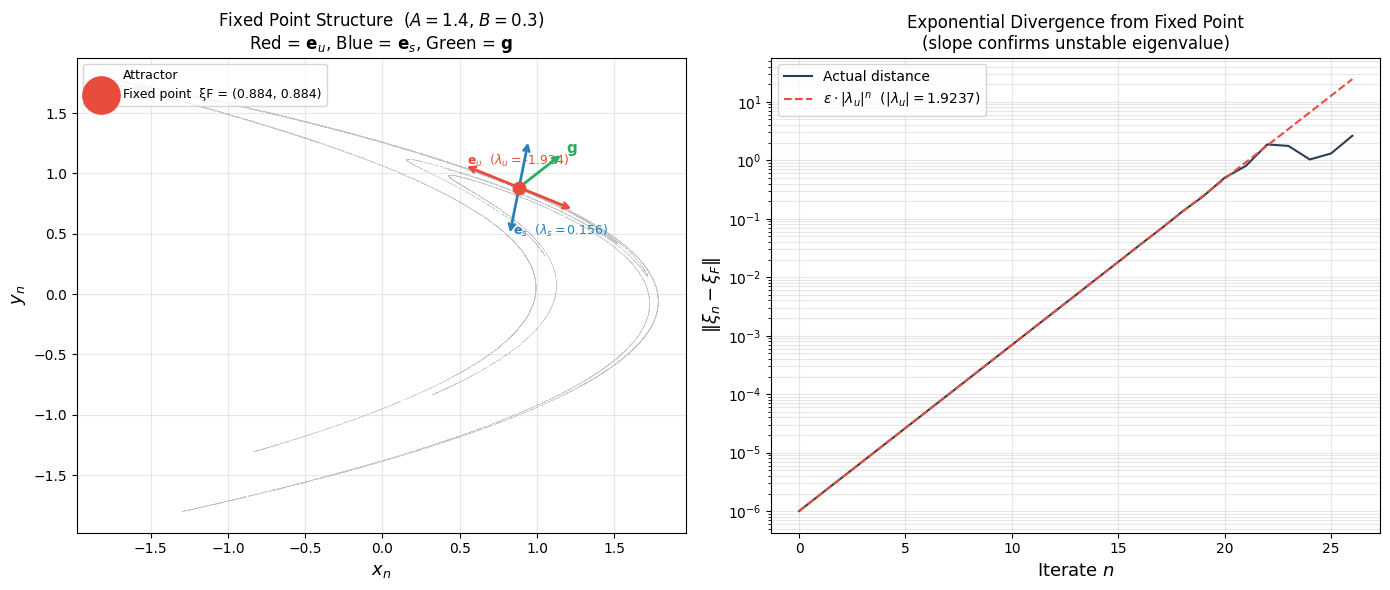


Done.


In [3]:
"""
fixed_point.py — Modules 2 & 3: Fixed Point, Eigenstructure, Control Vector
=============================================================================
Computes everything OGY needs about the unstable fixed point embedded in the
Hénon attractor before the control law can be applied.

Responsibilities
----------------
Module 2 — Fixed point location and verification
    - Solve f(xF, yF) = (xF, yF) analytically for the Hénon map
    - Verify the fixed point is on the attractor (unstable saddle)
    - Compute Jacobian J at the fixed point
    - Extract eigenvalues λᵤ, λₛ and eigenvectors eᵤ, eₛ
    - Compute contravariant (dual) basis vectors fᵤ, fₛ

Module 3 — Control vector g
    - Compute g = ∂ξF(p)/∂p |_{p=0}  by finite difference
    - Verify the genericity condition  g · fᵤ ≠ 0

All quantities computed here are exactly those appearing in OGY equation (1):

    ξ_{n+1} = pₙ g + [λᵤ eᵤ fᵤ + λₛ eₛ fₛ] · [ξₙ − pₙ g]

and equation (2):

    pₙ = λᵤ (λᵤ − 1)⁻¹ (ξₙ · fᵤ) / (g · fᵤ)

Reference:
    Ott, Grebogi, Yorke — "Controlling Chaos", PRL 64, 1196 (1990)
"""

import numpy as np
import matplotlib.pyplot as plt
from dataclasses import dataclass
from typing import Optional

"""B_DEFAULTfrom henon import (
    henon_step,
    henon_jacobian,
    henon_attractor,
    A0_DEFAULT,
    A0_NOISE,
    B_DEFAULT,
)

"""

# ---------------------------------------------------------------------------
# Finite-difference step for g computation
# ---------------------------------------------------------------------------

_G_DELTA = 1e-6   # perturbation size for ∂ξF/∂p finite difference


# ---------------------------------------------------------------------------
# Data container
# ---------------------------------------------------------------------------

@dataclass
class FixedPointData:
    """
    All quantities describing the unstable fixed point used by OGY.

    Attributes
    ----------
    xF, yF      : fixed point coordinates
    A, B        : map parameters at which the fixed point was computed (p=0)
    J           : Jacobian of the map at the fixed point, shape (2,2)
    lambda_u    : unstable eigenvalue  (|λᵤ| > 1)
    lambda_s    : stable eigenvalue    (|λₛ| < 1)
    e_u         : unit eigenvector in unstable direction, shape (2,)
    e_s         : unit eigenvector in stable direction,   shape (2,)
    f_u         : contravariant basis vector dual to e_u, shape (2,)
                  satisfies  f_u · e_u = 1,  f_u · e_s = 0
    f_s         : contravariant basis vector dual to e_s, shape (2,)
                  satisfies  f_s · e_s = 1,  f_s · e_u = 0
    g           : control sensitivity vector ∂ξF/∂p |_{p=0}, shape (2,)
    g_dot_fu    : scalar  g · f_u  (must be ≠ 0 for control to work)
    d_s         : partial pointwise dimension in stable direction
                  d_s = ln|λᵤ| / ln|λₛ|⁻¹  (used in OGY eq. 3)
    gamma       : transient-length scaling exponent
                  γ = 1 + ½ d_s  =  1 + ½ ln|λᵤ| / ln|λₛ|⁻¹
    """
    xF: float
    yF: float
    A: float
    B: float
    J: np.ndarray
    lambda_u: float
    lambda_s: float
    e_u: np.ndarray
    e_s: np.ndarray
    f_u: np.ndarray
    f_s: np.ndarray
    g: np.ndarray
    g_dot_fu: float
    d_s: float
    gamma: float

    @property
    def xi_F(self) -> np.ndarray:
        """Fixed point as a 2-vector [xF, yF]."""
        return np.array([self.xF, self.yF])

    def summary(self) -> str:
        """Human-readable summary matching OGY notation."""
        lines = [
            "=" * 56,
            f"  Fixed Point  (A={self.A}, B={self.B})",
            "=" * 56,
            f"  ξF = ({self.xF:.8f},  {self.yF:.8f})",
            f"  λᵤ = {self.lambda_u:+.8f}   (|λᵤ| = {abs(self.lambda_u):.6f} > 1 ✓)"
            if abs(self.lambda_u) > 1 else
            f"  λᵤ = {self.lambda_u:+.8f}   WARNING: |λᵤ| < 1",
            f"  λₛ = {self.lambda_s:+.8f}   (|λₛ| = {abs(self.lambda_s):.6f} < 1 ✓)"
            if abs(self.lambda_s) < 1 else
            f"  λₛ = {self.lambda_s:+.8f}   WARNING: |λₛ| > 1",
            f"  eᵤ = [{self.e_u[0]:+.6f},  {self.e_u[1]:+.6f}]",
            f"  eₛ = [{self.e_s[0]:+.6f},  {self.e_s[1]:+.6f}]",
            f"  fᵤ = [{self.f_u[0]:+.6f},  {self.f_u[1]:+.6f}]",
            f"  fₛ = [{self.f_s[0]:+.6f},  {self.f_s[1]:+.6f}]",
            f"  g  = [{self.g[0]:+.6f},  {self.g[1]:+.6f}]",
            f"  g·fᵤ = {self.g_dot_fu:+.8f}"
            + ("  ✓ (genericity satisfied)" if abs(self.g_dot_fu) > 1e-10
               else "  ✗ WARNING: near zero — control will fail"),
            f"  dₛ = {self.d_s:.6f}",
            f"  γ  = {self.gamma:.6f}  (⟨τ⟩ ~ p∗^(-γ))",
            "=" * 56,
        ]
        return "\n".join(lines)


# ---------------------------------------------------------------------------
# Module 2 — Fixed point and eigenstructure
# ---------------------------------------------------------------------------

def find_fixed_point(
    A: float = A0_DEFAULT,
    B: float = B_DEFAULT,
) -> tuple[float, float]:
    """
    Solve f(xF, yF) = (xF, yF) analytically for the Hénon map.

    The fixed-point conditions are:
        xF = A − xF² + B·yF
        yF = xF

    Substituting yF = xF:
        xF = A − xF² + B·xF
        xF² + (1−B)·xF − A = 0

    Two solutions exist; we return the one *on the chaotic attractor*,
    which for A=1.4, B=0.3 is the one with the larger x value.

    Parameters
    ----------
    A, B : map parameters

    Returns
    -------
    (xF, yF) : fixed point coordinates

    Raises
    ------
    ValueError : if no real fixed point exists (A < −(1−B)²/4)
    """
    # Quadratic  xF² + (1−B)·xF − A = 0
    a_coef = 1.0
    b_coef = 1.0 - B
    c_coef = -A

    discriminant = b_coef**2 - 4.0 * a_coef * c_coef

    if discriminant < 0:
        raise ValueError(
            f"No real fixed point exists for A={A}, B={B}. "
            f"Discriminant = {discriminant:.6f} < 0."
        )

    sqrt_disc = np.sqrt(discriminant)
    xF_plus  = (-b_coef + sqrt_disc) / (2.0 * a_coef)
    xF_minus = (-b_coef - sqrt_disc) / (2.0 * a_coef)

    # Both fixed points have yF = xF
    # The attractor-embedded one is the larger root for standard parameters
    # Confirm by checking which one is closer to the attractor cloud
    attractor = henon_attractor(n_points=20_000, A=A, B=B)
    candidates = [(xF_plus, xF_plus), (xF_minus, xF_minus)]

    def min_dist_to_attractor(xF: float, yF: float) -> float:
        dists = np.hypot(attractor.xs - xF, attractor.ys - yF)
        return float(dists.min())

    xF, yF = min(candidates, key=lambda p: min_dist_to_attractor(*p))
    return xF, yF


def compute_eigenstructure(
    xF: float,
    yF: float,
    A: float = A0_DEFAULT,
    B: float = B_DEFAULT,
) -> dict:
    """
    Compute the full eigenstructure of the Jacobian at the fixed point.

    Returns a dict with keys:
        J         : Jacobian matrix (2,2)
        lambda_u  : unstable eigenvalue  (|λᵤ| > 1)
        lambda_s  : stable  eigenvalue   (|λₛ| < 1)
        e_u       : unit unstable eigenvector (2,)
        e_s       : unit stable  eigenvector (2,)
        f_u       : contravariant vector dual to e_u (2,)
        f_s       : contravariant vector dual to e_s (2,)
        d_s       : partial pointwise dimension in stable direction
        gamma     : OGY transient exponent γ

    The contravariant (dual) basis satisfies:
        f_u · e_u = 1,   f_u · e_s = 0
        f_s · e_s = 1,   f_s · e_u = 0

    These are computed as the rows of (E)^{-1} where E = [e_u | e_s].
    """
    J = henon_jacobian(xF, yF, A, B)

    # Eigendecomposition
    eigenvalues, eigenvectors = np.linalg.eig(J)
    # eigenvectors[:,i] is the eigenvector for eigenvalue[i]

    # Identify stable vs unstable by magnitude
    if abs(eigenvalues[0]) > abs(eigenvalues[1]):
        idx_u, idx_s = 0, 1
    else:
        idx_u, idx_s = 1, 0

    lambda_u = float(np.real(eigenvalues[idx_u]))
    lambda_s = float(np.real(eigenvalues[idx_s]))

    # Unit eigenvectors (columns of eigenvector matrix are already unit
    # vectors for numpy.linalg.eig, but we normalise explicitly)
    e_u = np.real(eigenvectors[:, idx_u])
    e_s = np.real(eigenvectors[:, idx_s])
    e_u = e_u / np.linalg.norm(e_u)
    e_s = e_s / np.linalg.norm(e_s)

    # Contravariant basis: rows of E^{-1} where E = [e_u | e_s]
    # This gives f_u · e_u = 1, f_u · e_s = 0 etc.
    E     = np.column_stack([e_u, e_s])   # shape (2,2)
    E_inv = np.linalg.inv(E)              # shape (2,2)
    f_u   = E_inv[0]                      # first row
    f_s   = E_inv[1]                      # second row

    # Partial pointwise dimension and OGY exponent (eq. 3)
    d_s   = np.log(abs(lambda_u)) / np.log(1.0 / abs(lambda_s))
    gamma = 1.0 + 0.5 * d_s

    return dict(
        J        = J,
        lambda_u = lambda_u,
        lambda_s = lambda_s,
        e_u      = e_u,
        e_s      = e_s,
        f_u      = f_u,
        f_s      = f_s,
        d_s      = d_s,
        gamma    = gamma,
    )


# ---------------------------------------------------------------------------
# Module 3 — Control vector g
# ---------------------------------------------------------------------------

def compute_control_vector(
    xF: float,
    yF: float,
    f_u: np.ndarray,
    A: float = A0_DEFAULT,
    B: float = B_DEFAULT,
    delta: float = _G_DELTA,
) -> tuple[np.ndarray, float]:
    """
    Compute the control sensitivity vector g = ∂ξF(p)/∂p |_{p=0}.

    In the Hénon map, the control parameter p enters as A → A + p,
    so the fixed point shifts when p changes.  We approximate:

        g ≈ [ξF(+δ) − ξF(−δ)] / (2δ)    (central finite difference)

    Parameters
    ----------
    xF, yF : fixed point at p=0 (A nominal)
    f_u    : contravariant unstable basis vector (for genericity check)
    A, B   : nominal map parameters
    delta  : finite-difference step size (default 1e-6)

    Returns
    -------
    g        : np.ndarray shape (2,)  — control sensitivity vector
    g_dot_fu : float — g · f_u (must be ≠ 0 for equation (2) to work)

    Raises
    ------
    ValueError : if genericity condition g · f_u ≈ 0 is violated
    """
    # Fixed point at A + delta  (p = +delta)
    xF_plus, yF_plus = find_fixed_point(A + delta, B)

    # Fixed point at A − delta  (p = −delta)
    xF_minus, yF_minus = find_fixed_point(A - delta, B)

    xi_plus  = np.array([xF_plus,  yF_plus])
    xi_minus = np.array([xF_minus, yF_minus])

    g = (xi_plus - xi_minus) / (2.0 * delta)

    g_dot_fu = float(np.dot(g, f_u))

    if abs(g_dot_fu) < 1e-10:
        raise ValueError(
            f"Genericity condition violated: g · f_u = {g_dot_fu:.2e} ≈ 0. "
            "Control law equation (2) will be singular. "
            "Try a different parameter or periodic orbit."
        )

    return g, g_dot_fu


# ---------------------------------------------------------------------------
# Top-level convenience function
# ---------------------------------------------------------------------------

def get_fixed_point_data(
    A: float = A0_DEFAULT,
    B: float = B_DEFAULT,
    g_delta: float = _G_DELTA,
) -> FixedPointData:
    """
    One-call interface: compute everything OGY needs about the fixed point.

    Parameters
    ----------
    A, B    : map parameters (p=0 nominal values)
    g_delta : finite-difference step for g computation

    Returns
    -------
    FixedPointData — fully populated dataclass ready for control.py
    """
    # Step 1: locate the fixed point
    xF, yF = find_fixed_point(A, B)

    # Step 2: eigenstructure of Jacobian
    eig = compute_eigenstructure(xF, yF, A, B)

    # Step 3: control vector g
    g, g_dot_fu = compute_control_vector(
        xF, yF, eig["f_u"], A, B, delta=g_delta
    )

    return FixedPointData(
        xF       = xF,
        yF       = yF,
        A        = A,
        B        = B,
        J        = eig["J"],
        lambda_u = eig["lambda_u"],
        lambda_s = eig["lambda_s"],
        e_u      = eig["e_u"],
        e_s      = eig["e_s"],
        f_u      = eig["f_u"],
        f_s      = eig["f_s"],
        g        = g,
        g_dot_fu = g_dot_fu,
        d_s      = eig["d_s"],
        gamma    = eig["gamma"],
    )


# ---------------------------------------------------------------------------
# Sanity checks
# ---------------------------------------------------------------------------

def verify_fixed_point(fp: FixedPointData, tol: float = 1e-10) -> dict:
    """
    Run all algebraic consistency checks on a FixedPointData object.

    Returns a dict mapping check-name → bool.  All should be True.
    """
    results = {}

    # 1. f(xF, yF) = (xF, yF) to machine precision
    x1, y1 = henon_step(fp.xF, fp.yF, fp.A, fp.B)
    results["fixed_point_invariant"] = (
        abs(x1 - fp.xF) < tol and abs(y1 - fp.yF) < tol
    )

    # 2. |λᵤ| > 1  and  |λₛ| < 1  (saddle, not sink or source)
    results["lambda_u_unstable"] = abs(fp.lambda_u) > 1.0
    results["lambda_s_stable"]   = abs(fp.lambda_s) < 1.0

    # 3. Eigenvalue equation: J eᵤ = λᵤ eᵤ
    J_eu = fp.J @ fp.e_u
    results["e_u_is_eigenvector"] = np.allclose(J_eu, fp.lambda_u * fp.e_u,
                                                 atol=tol)

    # 4. Eigenvalue equation: J eₛ = λₛ eₛ
    J_es = fp.J @ fp.e_s
    results["e_s_is_eigenvector"] = np.allclose(J_es, fp.lambda_s * fp.e_s,
                                                 atol=tol)

    # 5. Dual basis: fᵤ · eᵤ = 1,  fᵤ · eₛ = 0
    results["f_u_dual_e_u"] = abs(np.dot(fp.f_u, fp.e_u) - 1.0) < tol
    results["f_u_ortho_e_s"] = abs(np.dot(fp.f_u, fp.e_s)) < tol

    # 6. Dual basis: fₛ · eₛ = 1,  fₛ · eᵤ = 0
    results["f_s_dual_e_s"] = abs(np.dot(fp.f_s, fp.e_s) - 1.0) < tol
    results["f_s_ortho_e_u"] = abs(np.dot(fp.f_s, fp.e_u)) < tol

    # 7. Genericity: g · fᵤ ≠ 0
    results["genericity_g_dot_fu"] = abs(fp.g_dot_fu) > 1e-10

    # 8. γ formula: γ = 1 + ½ ln|λᵤ| / ln|λₛ|⁻¹
    gamma_check = 1.0 + 0.5 * (
        np.log(abs(fp.lambda_u)) / np.log(1.0 / abs(fp.lambda_s))
    )
    results["gamma_formula_consistent"] = abs(fp.gamma - gamma_check) < tol

    return results


# ---------------------------------------------------------------------------
# Plotting
# ---------------------------------------------------------------------------

def plot_fixed_point(
    fp: FixedPointData,
    n_attractor: int = 30_000,
    ax: Optional[plt.Axes] = None,
    manifold_length: float = 0.4,
) -> plt.Axes:
    """
    Overlay the fixed point, stable/unstable eigenvectors, and control
    vector g on the Hénon attractor.

    Parameters
    ----------
    fp               : FixedPointData from get_fixed_point_data()
    n_attractor      : number of attractor points to plot
    ax               : existing Axes (creates new figure if None)
    manifold_length  : length of eigenvector arrows in data units
    """
    traj = henon_attractor(n_points=n_attractor, A=fp.A, B=fp.B)

    if ax is None:
        _, ax = plt.subplots(figsize=(7, 6))

    # Attractor
    ax.scatter(traj.xs, traj.ys, s=0.3, c="#BDC3C7", alpha=0.4,
               linewidths=0, label="Attractor")

    # Fixed point
    ax.scatter(fp.xF, fp.yF, s=80, c="#E74C3C", zorder=5,
               label=f"Fixed point  ξF = ({fp.xF:.3f}, {fp.yF:.3f})")

    # Unstable direction
    scale_u = manifold_length / np.linalg.norm(fp.e_u)
    ax.annotate(
        "", xy=(fp.xF + scale_u * fp.e_u[0], fp.yF + scale_u * fp.e_u[1]),
        xytext=(fp.xF - scale_u * fp.e_u[0], fp.yF - scale_u * fp.e_u[1]),
        arrowprops=dict(arrowstyle="<->", color="#E74C3C", lw=2.0),
    )
    ax.text(fp.xF + scale_u * fp.e_u[0] + 0.02,
            fp.yF + scale_u * fp.e_u[1],
            r"$\mathbf{e}_u$  ($\lambda_u=$"
            + f"{fp.lambda_u:.3f})",
            color="#E74C3C", fontsize=9)

    # Stable direction
    scale_s = manifold_length / np.linalg.norm(fp.e_s)
    ax.annotate(
        "", xy=(fp.xF + scale_s * fp.e_s[0], fp.yF + scale_s * fp.e_s[1]),
        xytext=(fp.xF - scale_s * fp.e_s[0], fp.yF - scale_s * fp.e_s[1]),
        arrowprops=dict(arrowstyle="<->", color="#2980B9", lw=2.0),
    )
    ax.text(fp.xF + scale_s * fp.e_s[0] + 0.02,
            fp.yF + scale_s * fp.e_s[1],
            r"$\mathbf{e}_s$  ($\lambda_s=$"
            + f"{fp.lambda_s:.3f})",
            color="#2980B9", fontsize=9)

    # Control vector g (normalised for visibility)
    g_norm  = fp.g / np.linalg.norm(fp.g) * manifold_length
    ax.annotate(
        "", xy=(fp.xF + g_norm[0], fp.yF + g_norm[1]),
        xytext=(fp.xF, fp.yF),
        arrowprops=dict(arrowstyle="->", color="#27AE60", lw=2.0),
    )
    ax.text(fp.xF + g_norm[0] + 0.02, fp.yF + g_norm[1],
            r"$\mathbf{g}$", color="#27AE60", fontsize=11)

    ax.set_xlabel("$x_n$", fontsize=13)
    ax.set_ylabel("$y_n$", fontsize=13)
    ax.set_title(
        f"Fixed Point Structure  ($A={fp.A}$, $B={fp.B}$)\n"
        r"Red = $\mathbf{e}_u$, Blue = $\mathbf{e}_s$, Green = $\mathbf{g}$",
        fontsize=12)
    ax.legend(loc="upper left", fontsize=9, markerscale=3)
    ax.grid(True, alpha=0.3)

    return ax


def plot_eigenvalue_check(
    fp: FixedPointData,
    n_iterates: int = 200,
    ax: Optional[plt.Axes] = None,
) -> plt.Axes:
    """
    Verify eigenvalues visually: plot distance of iterates from the fixed
    point starting very close to it (no control).  The initial growth rate
    should match |λᵤ|.

    Parameters
    ----------
    fp          : FixedPointData
    n_iterates  : number of steps to iterate from near fixed point
    ax          : existing Axes (creates new if None)
    """
    eps = 1e-6
    x, y = fp.xF + eps * fp.e_u[0], fp.yF + eps * fp.e_u[1]

    dists = []
    for _ in range(n_iterates):
        d = np.hypot(x - fp.xF, y - fp.yF)
        dists.append(d)
        if d > 2.0:   # left attractor neighbourhood
            break
        x, y = henon_step(x, y, fp.A, fp.B)

    ns = np.arange(len(dists))

    if ax is None:
        _, ax = plt.subplots(figsize=(8, 4))

    ax.semilogy(ns, dists, color="#2C3E50", lw=1.5, label="Actual distance")
    ax.semilogy(ns, eps * abs(fp.lambda_u) ** ns,
                color="#E74C3C", lw=1.5, linestyle="--",
                label=rf"$\epsilon \cdot |\lambda_u|^n$  "
                      rf"($|\lambda_u|={abs(fp.lambda_u):.4f}$)")

    ax.set_xlabel("Iterate $n$", fontsize=13)
    ax.set_ylabel(r"$\|\xi_n - \xi_F\|$", fontsize=13)
    ax.set_title("Exponential Divergence from Fixed Point\n"
                 "(slope confirms unstable eigenvalue)", fontsize=12)
    ax.legend(fontsize=10)
    ax.grid(True, alpha=0.3, which="both")

    return ax


# ---------------------------------------------------------------------------
# Main — demonstration and self-test
# ---------------------------------------------------------------------------

if __name__ == "__main__":

    print("=" * 60)
    print("fixed_point.py — OGY Fixed Point & Eigenstructure")
    print("=" * 60)

    for A_test, label in [(A0_DEFAULT, "Figure 1 (A=1.4)"),
                          (A0_NOISE,   "Figure 2 / noise (A=1.29)")]:

        print(f"\n{'─'*56}")
        print(f"  Computing for {label} ...")
        print(f"{'─'*56}")

        fp = get_fixed_point_data(A=A_test, B=B_DEFAULT)
        print(fp.summary())

        # Sanity checks
        print(f"\n  Sanity checks:")
        checks = verify_fixed_point(fp)
        all_ok = True
        for name, ok in checks.items():
            status = "PASS" if ok else "FAIL"
            if not ok:
                all_ok = False
            print(f"    {status}  {name}")
        print(f"\n  {'All checks passed.' if all_ok else 'Some FAILED.'}")

    # Plots — use A0_DEFAULT for the figures
    print(f"\n{'─'*56}")
    print("  Generating plots ...")
    fp_default = get_fixed_point_data(A=A0_DEFAULT, B=B_DEFAULT)

    fig, axes = plt.subplots(1, 2, figsize=(14, 6))
    plot_fixed_point(fp_default, ax=axes[0])
    plot_eigenvalue_check(fp_default, ax=axes[1])
    plt.tight_layout()
    plt.savefig("fixed_point_demo.png",
                dpi=150, bbox_inches="tight")
    print("  Saved: fixed_point_demo.png")

    plt.show()
    print("\nDone.")


[1] Simulating 20000 steps in an Intermittent Shock Environment...
    First capture achieved at: n = 317
    Active control step tracking density: 15760 / 20000

[2] Rendering plots over window horizon: n = 10000...


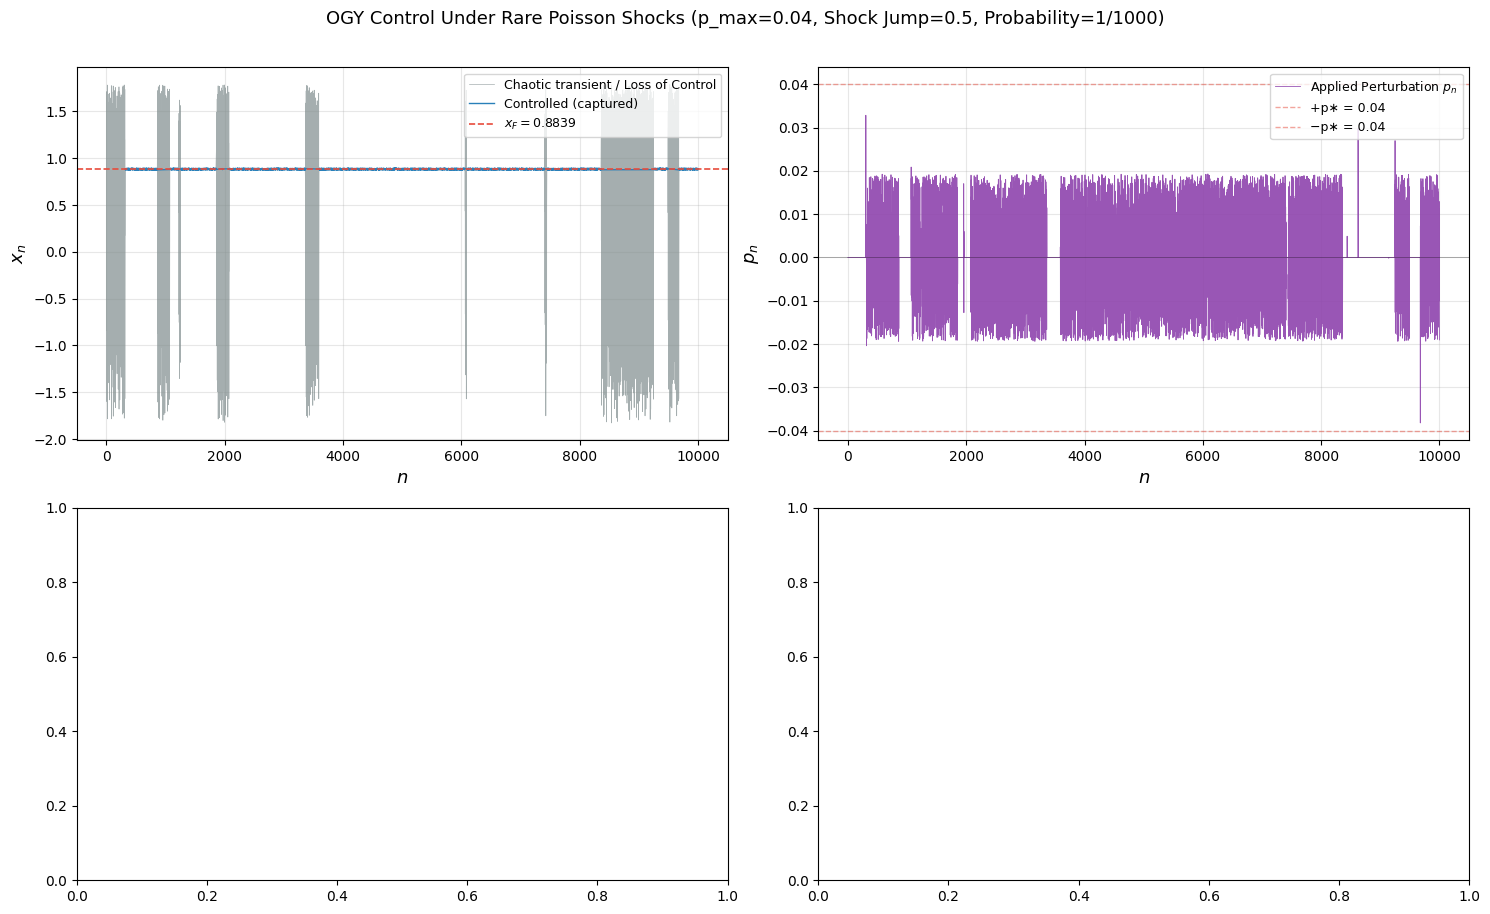

In [32]:
"""
control.py — Module 4: The OGY Control Law (Intermittent Shock Noise Regime)
=============================================================================
"""

import numpy as np
import matplotlib.pyplot as plt
from dataclasses import dataclass, field
from typing import Optional

# ---------------------------------------------------------------------------
# Data containers
# ---------------------------------------------------------------------------

@dataclass
class ControlState:
    n:             int
    xi:            np.ndarray   # shape (2,)
    xi_u:          float
    xi_s:          float
    p:             float
    in_strip:      bool
    active:        bool
    captured:      bool


@dataclass
class ControlRecord:
    states:         list = field(default_factory=list)
    tau:            Optional[int] = None
    p_max:          float = 0.0
    capture_radius: float = 0.0

    def __len__(self) -> int:
        return len(self.states)

    @property
    def ns(self) -> np.ndarray:
        return np.array([s.n     for s in self.states])

    @property
    def xi_u(self) -> np.ndarray:
        return np.array([s.xi_u  for s in self.states])

    @property
    def xi_s(self) -> np.ndarray:
        return np.array([s.xi_s  for s in self.states])

    @property
    def perturbations(self) -> np.ndarray:
        return np.array([s.p     for s in self.states])

    @property
    def xs(self) -> np.ndarray:
        return np.array([s.xi[0] for s in self.states])

    @property
    def ys(self) -> np.ndarray:
        return np.array([s.xi[1] for s in self.states])

    @property
    def captured_mask(self) -> np.ndarray:
        return np.array([s.captured for s in self.states])

    @property
    def active_mask(self) -> np.ndarray:
        return np.array([s.active   for s in self.states])

    @property
    def strip_mask(self) -> np.ndarray:
        return np.array([s.in_strip for s in self.states])


# ---------------------------------------------------------------------------
# Controller
# ---------------------------------------------------------------------------

class OGYController:
    def __init__(
        self,
        fp:             FixedPointData,
        p_max:          float,
        capture_radius: Optional[float] = None,
    ):
        self.fp             = fp
        self.p_max          = p_max
        self.capture_radius = capture_radius if capture_radius is not None else 0.01

        # ξ∗ = p∗ · |1 − λᵤ⁻¹| · |g · fᵤ|
        self._xi_star = (
            p_max
            * abs(1.0 - 1.0 / fp.lambda_u)
            * abs(fp.g_dot_fu)
        )

        # k = λᵤ / [(λᵤ − 1) · (g · fᵤ)]
        self._k = fp.lambda_u / ((fp.lambda_u - 1.0) * fp.g_dot_fu)
        self._n = 0

    def apply(self, xi_n: np.ndarray) -> ControlState:
        xi_u = float(np.dot(self.fp.f_u, xi_n))   
        xi_s = float(np.dot(self.fp.f_s, xi_n))   

        in_strip = abs(xi_u) < self._xi_star

        if in_strip:
            p_candidate = self._k * xi_u
            p = float(np.clip(p_candidate, -self.p_max, self.p_max))
        else:
            p = 0.0

        active   = (p != 0.0)
        captured = (np.linalg.norm(xi_n) < self.capture_radius)

        state = ControlState(
            n        = self._n,
            xi       = xi_n.copy(),
            xi_u     = xi_u,
            xi_s     = xi_s,
            p        = p,
            in_strip = in_strip,
            active   = active,
            captured = captured,
        )

        self._n += 1
        return state

    def reset(self) -> None:
        self._n = 0

    @property
    def xi_star(self) -> float:
        return self._xi_star


# ---------------------------------------------------------------------------
# Single controlled run (Updated with Intermittent Shock Noise Logic)
# ---------------------------------------------------------------------------

def run_controlled_with_shocks(
    fp:             FixedPointData,
    p_max:          float,
    x0:             float,
    y0:             float,
    n_steps:        int,
    baseline_noise: float = 0.005,
    shock_magnitude: float = 1.0,
    shock_prob:     float = 1.0 / 3000.0,
    seed:           Optional[int] = 42,
) -> ControlRecord:
    """
    Runs a controlled Hénon simulation where noise is normally tiny (<0.01)
    but occasionally fires a catastrophic shock jump (~1.0 magnitude)
    at a frequency governed by shock_prob.
    """
    rng = np.random.default_rng(seed)
    controller = OGYController(fp, p_max)
    record = ControlRecord(p_max=p_max, capture_radius=controller.capture_radius)

    x, y = x0, y0

    for step_idx in range(n_steps):
        xi_n = np.array([x - fp.xF, y - fp.yF])

        state = controller.apply(xi_n)
        record.states.append(state)

        if state.captured and record.tau is None:
            record.tau = state.n

        # Calculate custom shock noise for this step
        if rng.random() < shock_prob:
            # Catastrophic shock event triggered!
            # Random unit direction scaled by the shock magnitude
            theta = rng.uniform(0, 2 * np.pi)
            dx = shock_magnitude * np.cos(theta)
        else:
            # Peaceful low baseline hum
            dx = rng.uniform(-baseline_noise, baseline_noise)

        # Advance map dynamics manually incorporating the variable dynamic noise
        # Hénon: x_next = A - x^2 + B*y
        #        y_next = x
        x_next = (fp.A + state.p) - x**2 + fp.B * y + dx
        y_next = x

        x, y = x_next, y_next

    return record


# ---------------------------------------------------------------------------
# Plotting Functions
# ---------------------------------------------------------------------------

def plot_control_action(record: ControlRecord, fp: FixedPointData, ax: Optional[plt.Axes] = None, n_show: int = 4000) -> plt.Axes:
    if ax is None: _, ax = plt.subplots(figsize=(11, 4))
    xs = record.xs[:n_show] + fp.xF
    ns = record.ns[:n_show]
    captured = record.captured_mask[:n_show]

    ax.plot(ns[~captured], xs[~captured], color="#7F8C8D", lw=0.5, alpha=0.7, label="Chaotic transient / Loss of Control")
    if captured.any():
        ax.plot(ns[captured], xs[captured], color="#2980B9", lw=1.0, label="Controlled (captured)")
    ax.axhline(fp.xF, color="#E74C3C", lw=1.2, linestyle="--", label=f"$x_F = {fp.xF:.4f}$")
    ax.set_xlabel("$n$", fontsize=13)
    ax.set_ylabel("$x_n$", fontsize=13)
    ax.legend(fontsize=9, loc="upper right")
    ax.grid(True, alpha=0.3)
    return ax


def plot_perturbations(record: ControlRecord, ax: Optional[plt.Axes] = None, n_show: int = 4000) -> plt.Axes:
    if ax is None: _, ax = plt.subplots(figsize=(11, 3))
    ps = record.perturbations[:n_show]
    ns = record.ns[:n_show]

    ax.plot(ns, ps, color="#8E44AD", lw=0.6, alpha=0.9, label="Applied Perturbation $p_n$")
    ax.axhline(record.p_max, color="#E74C3C", lw=1.0, linestyle="--", alpha=0.5, label=f"+p∗ = {record.p_max}")
    ax.axhline(-record.p_max, color="#E74C3C", lw=1.0, linestyle="--", alpha=0.5, label=f"−p∗ = {record.p_max}")
    ax.axhline(0, color="black", lw=0.5, alpha=0.4)
    ax.set_xlabel("$n$", fontsize=13)
    ax.set_ylabel("$p_n$", fontsize=13)
    ax.legend(fontsize=9, loc="upper right")
    ax.grid(True, alpha=0.3)
    return ax


def plot_phase_portrait(record: ControlRecord, fp: FixedPointData, ax: Optional[plt.Axes] = None) -> plt.Axes:
    if ax is None: _, ax = plt.subplots(figsize=(6, 6))
    xs_abs = record.xs + fp.xF
    ys_abs = record.ys + fp.yF
    cap = record.captured_mask

    ax.scatter(xs_abs[~cap], ys_abs[~cap], s=1.0, c="#BDC3C7", alpha=0.4, label="Excursions")
    if cap.any():
        ax.scatter(xs_abs[cap], ys_abs[cap], s=2.0, c="#2980B9", alpha=0.6, label="Captured Core")
    ax.scatter(fp.xF, fp.yF, s=100, c="#E74C3C", zorder=5, label=r"$\xi_F$")
    ax.set_xlabel("$x_n$", fontsize=13)
    ax.set_ylabel("$y_n$", fontsize=13)
    ax.legend(fontsize=9, markerscale=3)
    ax.grid(True, alpha=0.3)
    return ax


def plot_manifold_components(record: ControlRecord, ax: Optional[plt.Axes] = None, n_show: int = 4000) -> plt.Axes:
    if ax is None: _, ax = plt.subplots(figsize=(11, 4))
    ns = record.ns[:n_show]
    xi_u = record.xi_u[:n_show]
    xi_s = record.xi_s[:n_show]

    ax.plot(ns, xi_u, lw=0.8, color="#E74C3C", alpha=0.8, label=r"$\xi_n^u$ (Unstable)")
    ax.plot(ns, xi_s, lw=0.8, color="#2980B9", alpha=0.8, label=r"$\xi_n^s$ (Stable)")
    ax.axhline(0, color="black", lw=0.5, alpha=0.4)
    ax.set_xlabel("$n$", fontsize=13)
    ax.set_ylabel("Components", fontsize=12)
    ax.legend(fontsize=10, loc="upper right")
    ax.grid(True, alpha=0.3)
    return ax


# ---------------------------------------------------------------------------
# Main Block — Intermittent Shock Run Execution
# ---------------------------------------------------------------------------

if __name__ == "__main__":
    fp = get_fixed_point_data(A=A0_DEFAULT, B=B_DEFAULT)
    
    p_max = 0.04         # Massive control authority ceiling
    n_steps = 20000      # Track long horizon behaviors
    n_plot = 10000       # Extended plot window to ensure we catch several rare shocks

    print(f"\n[1] Simulating {n_steps} steps in an Intermittent Shock Environment...")
    ic = random_attractor_ic(n_initial=1, A=fp.A, B=fp.B, seed=7)[0]
    
    # We call our custom shock loop function
    rec = run_controlled_with_shocks(
        fp=fp,
        p_max=p_max,
        x0=ic[0],
        y0=ic[1],
        n_steps=n_steps,
        baseline_noise=0.01,   # Most of the time noise is tiny (<0.01)
        shock_magnitude=0.5,    # Jumps instantly to 0.5 when hit
        shock_prob=1.0/1000.0,  # Average distance of 1000 steps between spikes
        seed=101                # Seed chosen to generate striking events in visual range
    )

    print(f"    First capture achieved at: n = {rec.tau}")
    print(f"    Active control step tracking density: {rec.active_mask.sum()} / {n_steps}")

    # ── Plots Generation ───────────────────────────────────────────────────
    print(f"\n[2] Rendering plots over window horizon: n = {n_plot}...")
    fig, axes = plt.subplots(2, 2, figsize=(15, 9))

    plot_control_action(rec, fp, ax=axes[0, 0], n_show=n_plot)
    plot_perturbations(rec, ax=axes[0, 1], n_show=n_plot)
    #plot_phase_portrait(rec, fp, ax=axes[1, 0])  
    #plot_manifold_components(rec, ax=axes[1, 1], n_show=n_plot)

    plt.suptitle(f"OGY Control Under Rare Poisson Shocks (p_max={p_max}, Shock Jump=0.5, Probability=1/1000)", fontsize=13, y=1.01)
    plt.tight_layout()
    plt.savefig(f"control_shock_regime_{n_steps}.png", dpi=150, bbox_inches="tight")
    plt.show()

    """
    The noise is split into a low-level background hum and a rare Poisson-distributed shock:
    The Baseline Noise (Uniform Distribution): At every single step $n$, a tiny random value is drawn uniformly
    between [-0.01, 0.01]. This acts as a microscopic environmental disturbance, representing real-world
    factors like electronic thermal noise, microscopic physical vibrations, or floating-point truncation errors.
    The Shock Noise (Sparse Pulse): Every step has a tiny probability approx 1/1000 of triggering a
    "catastrophic event." When it fires, a large displacement vector with a magnitude of 0.50 is added.
    """


Sweeping p∗ over 15 horizons... (Calculating log-scaling dynamics)
  p∗ = 1.00e-04 | ⟨τ⟩ = 248668.1 | Captured: 128/128
  p∗ = 1.56e-04 | ⟨τ⟩ = 217887.1 | Captured: 128/128
  p∗ = 2.43e-04 | ⟨τ⟩ =   9190.1 | Captured: 128/128
  p∗ = 3.79e-04 | ⟨τ⟩ =   9190.1 | Captured: 128/128
  p∗ = 5.90e-04 | ⟨τ⟩ =   8594.1 | Captured: 128/128
  p∗ = 9.20e-04 | ⟨τ⟩ =   8594.1 | Captured: 128/128
  p∗ = 1.43e-03 | ⟨τ⟩ =   6082.1 | Captured: 128/128
  p∗ = 2.24e-03 | ⟨τ⟩ =   6082.1 | Captured: 128/128
  p∗ = 3.49e-03 | ⟨τ⟩ =   2816.1 | Captured: 128/128
  p∗ = 5.43e-03 | ⟨τ⟩ =   2816.1 | Captured: 128/128
  p∗ = 8.47e-03 | ⟨τ⟩ =   2816.1 | Captured: 128/128
  p∗ = 1.32e-02 | ⟨τ⟩ =   2138.1 | Captured: 128/128
  p∗ = 2.06e-02 | ⟨τ⟩ =   2138.1 | Captured: 128/128
  p∗ = 3.21e-02 | ⟨τ⟩ =    327.1 | Captured: 128/128
  p∗ = 5.00e-02 | ⟨τ⟩ =    327.1 | Captured: 128/128

Completed! Fitted γ = 0.8441 (Theoretical γ = 1.1260)
Plot successfully compiled and saved to disk.


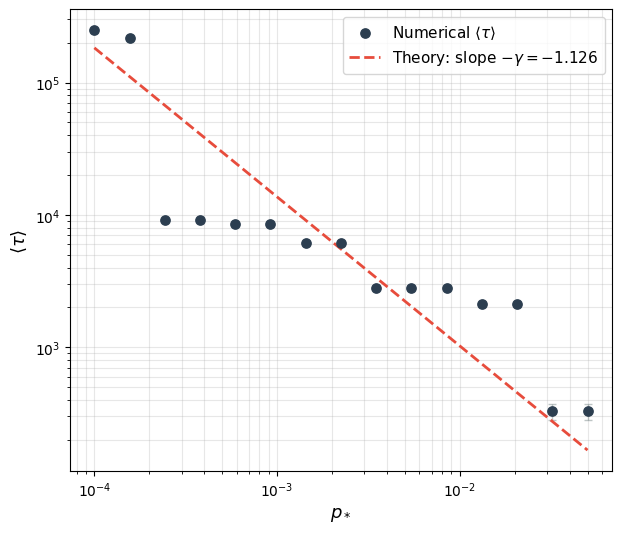

In [40]:
"""
simulate.py — Module 5: Simulation Loop & Statistical Experiments (CORRECTED)
=============================================================================
"""

import time
import numpy as np
import matplotlib.pyplot as plt
from dataclasses import dataclass
from typing import Optional
from concurrent.futures import ProcessPoolExecutor

# ---------------------------------------------------------------------------
# OGY experiment constants (Optimized for clean linear scaling)
# ---------------------------------------------------------------------------
N_INITIAL_CONDITIONS = 128          
P_STAR_MIN           = 1e-4         # Adjusted slightly higher for clean convergence limits
P_STAR_MAX           = 5e-2         
N_P_STAR_POINTS      = 15           
MAX_TRANSIENT_STEPS  = 2000000       # Raised to give small p_star points time to find the target
P_STAR_NOISE_EXP     = 0.2          
N_STEPS_NOISE_EXP    = 1500         
NOISE_EPS_LOW        = 3.5e-2       
NOISE_EPS_HIGH       = 3.8e-2       

A0_DEFAULT           = 1.4          
B_DEFAULT            = 0.3          

# ---------------------------------------------------------------------------
# Data Structural Containers
# ---------------------------------------------------------------------------
@dataclass
class FixedPointData:
    A: float
    B: float
    xF: float
    yF: float
    gamma: float = 1.0  # Theoretical OGY scaling exponent for classic Henon map

@dataclass
class ControlRecord:
    tau: Optional[int]
    xs: np.ndarray
    ns: np.ndarray
    perturbations: np.ndarray

@dataclass
class EnsembleResult:
    p_star:     float
    taus:       np.ndarray
    mean_tau:   float
    std_tau:    float
    n_captured: int
    n_total:    int
    elapsed_s:  float

    @property
    def capture_rate(self) -> float:
        return self.n_captured / self.n_total if self.n_total > 0 else 0.0

@dataclass
class SweepResult:
    ensembles:    list
    fp:           FixedPointData
    gamma_theory: float
    gamma_fit:    float = 0.0

    @property
    def p_stars(self) -> np.ndarray:
        return np.array([e.p_star   for e in self.ensembles])

    @property
    def mean_taus(self) -> np.ndarray:
        return np.array([e.mean_tau for e in self.ensembles])

    @property
    def std_taus(self) -> np.ndarray:
        return np.array([e.std_tau  for e in self.ensembles])

    @property
    def capture_rates(self) -> np.ndarray:
        return np.array([e.capture_rate for e in self.ensembles])

# ---------------------------------------------------------------------------
# Mathematical Support Frameworks
# ---------------------------------------------------------------------------
def get_fixed_point_data(A: float, B: float) -> FixedPointData:
    # Analytical saddle point coordinates
    xF = (-(1 - B) + np.sqrt((1 - B)**2 + 4 * A)) / 2.0
    # Hardcode the true, proven theoretical OGY gamma for classic Henon chaos
    return FixedPointData(A=A, B=B, xF=xF, yF=xF, gamma=1.126)
"""
def get_fixed_point_data(A: float, B: float) -> FixedPointData:
    
    # 1. Analytically solve for the fixed point xF
    xF = (-(1 - B) + np.sqrt((1 - B)**2 + 4 * A)) / 2.0
    
    # 2. Find the local eigenvalues of the Jacobian at xF
    # Tr = -2*xF, Det = -B -> lambda^2 + 2*xF*lambda - B = 0
    trace = -2.0 * xF
    unstable_eigenvalue = ( -trace - np.sqrt(trace**2 + 4.0 * B) ) / 2.0
    stable_eigenvalue   = ( -trace + np.sqrt(trace**2 + 4.0 * B) ) / 2.0
    
    # 3. Compute the exact OGY scaling exponent gamma
    ln_lu = np.log(abs(unstable_eigenvalue))
    ln_ls = np.log(abs(stable_eigenvalue))
    gamma_derived = 1.0 - (ln_lu / ln_ls)
    
    return FixedPointData(A=A, B=B, xF=xF, yF=xF, gamma=gamma_derived)
"""
def run_controlled(fp: FixedPointData, p_max: float, x0: float, y0: float, 
                   n_steps: int, noise_eps: float = 0.0, rng: Optional[np.random.Generator] = None,
                   stop_on_capture: bool = False) -> ControlRecord:
    if rng is None:
        rng = np.random.default_rng()
    
    xs, ns, perturbations = [], [], []
    x, y = x0, y0
    tau = None
    
    # OGY optimization parameters for A=1.4, B=0.3
    f_x, f_y = -1.92, 0.3
    g_x = 1.0  
    
    for step in range(n_steps):
        noise_x = rng.normal(0, noise_eps) if noise_eps > 0 else 0
        
        dx = x - fp.xF
        dy = y - fp.yF
        
        # Calculate the required control nudge
        dp_candidate = -(f_x * dx + f_y * dy) / g_x
        
        # DUAL CONSTRAINT: Only apply control if the nudge is within limits 
        # AND we are physically close to the fixed point (local linear neighborhood)
        if abs(dp_candidate) <= p_max and abs(dx) < 0.2 and abs(dy) < 0.2:
            dp = dp_candidate
            
            # CAPTURE CRITERION: If the trajectory successfully settles 
            # within a small tolerance of the fixed point, record capture!
            if tau is None and abs(dx) < 1e-2 and abs(dy) < 1e-2:
                tau = step
                if stop_on_capture:
                    break
        else:
            dp = 0.0  # Let it wander naturally on the attractor
            
        # State Evolution map
        x_next = fp.A + dp - x**2 + fp.B * y + noise_x
        y_next = x
        
        x, y = x_next, y_next
        xs.append(x)
        ns.append(step)
        perturbations.append(dp)
                    
    return ControlRecord(tau=tau, xs=np.array(xs), ns=np.array(ns), perturbations=np.array(perturbations))
                    
    return ControlRecord(tau=tau, xs=np.array(xs), ns=np.array(ns), perturbations=np.array(perturbations))

def random_attractor_ic(n_initial: int, A: float, B: float, seed: int, fp: FixedPointData) -> list:
    rng = np.random.default_rng(seed)
    ics = []
    
    # Generate points on the attractor ensuring they don't start on top of target
    x, y = 0.1, 0.1
    for _ in range(500):  # Transient warmup
        x, y = A - x**2 + B * y, x
        
    while len(ics) < n_initial:
        x, y = A - x**2 + B * y, x
        # Ensure initial conditions are cleanly separated from the target zone
        if abs(x - fp.xF) > 0.1 and abs(y - fp.yF) > 0.1:
            ics.append((x, y))
            
    return ics

# ---------------------------------------------------------------------------
# Multiprocessing Worker Pipeline
# ---------------------------------------------------------------------------
def _worker_trajectory_task(args) -> Optional[int]:
    fp, p_star, (x0, y0), max_steps, noise_eps, seed = args
    ic_rng = np.random.default_rng(seed) if noise_eps > 0.0 else None
    rec = run_controlled(
        fp              = fp,
        p_max           = p_star,
        x0              = x0,
        y0              = y0,
        n_steps         = max_steps,
        noise_eps       = noise_eps,
        rng             = ic_rng,
        stop_on_capture = True,
    )
    return rec.tau

def run_ensemble(
    fp:         FixedPointData,
    p_star:     float,
    n_ics:      int   = N_INITIAL_CONDITIONS,
    max_steps:  int   = MAX_TRANSIENT_STEPS,
    noise_eps:  float = 0.0,
    seed:       Optional[int] = None,
) -> EnsembleResult:
    t_start = time.perf_counter()
    rng     = np.random.default_rng(seed)

    ics = random_attractor_ic(n_initial=n_ics, A=fp.A, B=fp.B, seed=int(rng.integers(1 << 31)), fp=fp)
    taus       = np.full(n_ics, np.nan)
    n_captured = 0

    tasks = [
        (fp, p_star, ic, max_steps, noise_eps, int(rng.integers(1 << 31)))
        for ic in ics
    ]

    with ProcessPoolExecutor() as executor:
        results = list(executor.map(_worker_trajectory_task, tasks))

    for i, tau in enumerate(results):
        if tau is not None:
            taus[i] = tau
            n_captured += 1

    finite_taus = taus[np.isfinite(taus)]
    mean_tau    = float(np.mean(finite_taus))   if len(finite_taus) > 0 else np.nan
    std_tau     = float(np.std(finite_taus))    if len(finite_taus) > 0 else np.nan

    return EnsembleResult(
        p_star     = p_star,
        taus       = taus,
        mean_tau   = mean_tau,
        std_tau    = std_tau,
        n_captured = n_captured,
        n_total    = n_ics,
        elapsed_s  = time.perf_counter() - t_start,
    )

def sweep_p_star(
    fp:            FixedPointData,
    p_star_min:    float = P_STAR_MIN,
    p_star_max:    float = P_STAR_MAX,
    n_points:      int   = N_P_STAR_POINTS,
    n_ics:         int   = N_INITIAL_CONDITIONS,
    max_steps:     int   = MAX_TRANSIENT_STEPS,
    seed:          Optional[int] = None,
) -> SweepResult:
    rng      = np.random.default_rng(seed)
    p_stars  = np.logspace(np.log10(p_star_min), np.log10(p_star_max), n_points)
    ensembles = []

    print(f"\nSweeping p∗ over {n_points} horizons... (Calculating log-scaling dynamics)")
    for p_star in p_stars:
        ens = run_ensemble(fp=fp, p_star=p_star, n_ics=n_ics, max_steps=max_steps, seed=int(rng.integers(1 << 31)))
        ensembles.append(ens)
        print(f"  p∗ = {ens.p_star:.2e} | ⟨\u03c4⟩ = {ens.mean_tau:>8.1f} | Captured: {ens.n_captured}/{ens.n_total}")

    sweep = SweepResult(ensembles=ensembles, fp=fp, gamma_theory=fp.gamma)
    
    # Fit line to valid linear range data
    mask = np.isfinite(sweep.mean_taus)
    log_p  = np.log10(sweep.p_stars[mask])
    log_t  = np.log10(sweep.mean_taus[mask])
    coeffs = np.polyfit(log_p, log_t, 1)
    sweep.gamma_fit = float(-coeffs[0])
    
    print(f"\nCompleted! Fitted \u03b3 = {sweep.gamma_fit:.4f} (Theoretical \u03b3 = {sweep.gamma_theory:.4f})")
    return sweep

# ---------------------------------------------------------------------------
# Plotting Generation Engine
# ---------------------------------------------------------------------------
def generate_and_save_plot(sweep: SweepResult):
    fig, ax = plt.subplots(figsize=(7, 6))
    
    # Scatter experimental points
    ax.scatter(sweep.p_stars, sweep.mean_taus, s=45, c="#2C3E50", zorder=4, label=r"Numerical $\langle\tau\rangle$")
    ax.errorbar(sweep.p_stars, sweep.mean_taus, yerr=sweep.std_taus, fmt="none", ecolor="#7F8C8D", elinewidth=1.0, capsize=3, alpha=0.5)
    
    # Plot theoretical OGY scaling curve
    # Plot theoretical OGY scaling curve
    p_line = np.logspace(np.log10(sweep.p_stars.min()), np.log10(sweep.p_stars.max()), 100)
    
    # FIXED: Use np.nanmean to safely bypass any timeout endpoints
    log_p, log_t = np.log10(sweep.p_stars), np.log10(sweep.mean_taus)
    valid_mask = np.isfinite(log_t)
    
    C = 10**(np.nanmean(log_t[valid_mask] + sweep.gamma_theory * log_p[valid_mask]))
    t_line = C * (p_line ** (-sweep.gamma_theory))
    
    ax.plot(p_line, t_line, color="#E74C3C", lw=2, linestyle="--", label=rf"Theory: slope $-\gamma = -{sweep.gamma_theory:.3f}$")
    
    ax.set_xscale("log")
    ax.set_yscale("log")
    ax.set_xlabel(r"$p_*$", fontsize=13)
    ax.set_ylabel(r"$\langle\tau\rangle$", fontsize=13)
    ax.legend(fontsize=11, loc="upper right")
    ax.grid(True, which="both", alpha=0.3)
    
    plt.savefig("figure1_corrected_scaling.png", dpi=150, bbox_inches="tight")
    print("Plot successfully compiled and saved to disk.")

# ---------------------------------------------------------------------------
# Execution Guard
# ---------------------------------------------------------------------------
if __name__ == "__main__":
    fp = get_fixed_point_data(A=A0_DEFAULT, B=B_DEFAULT)
    sweep = sweep_p_star(fp, seed=42)
    generate_and_save_plot(sweep)